# Estimating Income Inequality in South Africa with Bootstrapping

**Research question:** How unequal are observed incomes in a 2017 South African survey, and how uncertain are estimates of within-group inequality?

This independently documented portfolio analysis applies methods practised in LSE PP422. It is not a reproduction of the assessed problem-set text. **The survey file is not redistributed**; place your authorised copy of `palms_clean.csv` alongside this notebook to run it.

The P90/P10 ratio divides the 90th-percentile income by the 10th-percentile income. It measures dispersion *within* a distribution, not the income gap *between* population groups. The analysis is descriptive, not causal. The dataset has no survey weights or design information, so intervals from the simple bootstrap should not be interpreted as survey-design-corrected population intervals.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('palms_clean.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Place your authorised palms_clean.csv copy next to this notebook.')
raw = pd.read_csv(DATA_PATH)
print('Raw rows:', len(raw))
print('Available years:', sorted(raw['year'].dropna().unique()))
print('Missing income values:', raw['imputed_real'].isna().sum())

Raw rows: 191020
Available years: [np.int64(2017)]
Missing income values: 129232


## 1. Prepare the income sample

Exclude observations missing `imputed_real`, retain the original population-group codes, and label them according to the categories used in the course dataset. No additional observations are removed. All incomes in the retained sample are positive.

In [2]:
labels = {1:'African/Black', 2:'Coloured', 3:'Indian/Asian', 4:'White', 5:'Other', 9:'Unspecified'}
data = raw.dropna(subset=['imputed_real']).copy()
data['population_group'] = data['popgroup'].map(labels)
assert (data['imputed_real'] > 0).all(), 'P90/P10 requires positive 10th-percentile income.'
print('Retained observations:', len(data))
display(data['population_group'].value_counts().rename('observations').to_frame())

Retained observations: 61788


,observations
population_group,
African/Black,49936
White,5359
Coloured,5034
Indian/Asian,1459


## 2. Estimate income inequality

The ratio compares the income at the 90th percentile with the income at the 10th percentile. It does not measure average income or the difference between group means.

In [3]:
def p90_p10(values):
    values = np.asarray(values, dtype=float)
    p10, p90 = np.quantile(values, [0.10, 0.90])
    if p10 <= 0:
        raise ValueError('The 10th percentile must be positive.')
    return p90 / p10

income = data['imputed_real'].to_numpy()
overall = p90_p10(income)
print(f'Overall P90/P10: {overall:.2f}')
group_summary = (data.groupby('population_group')['imputed_real']
                 .agg(observations='count', p90_p10=p90_p10)
                 .sort_values('p90_p10', ascending=False))
display(group_summary.round(2))

Overall P90/P10: 23.41


,observations,p90_p10
population_group,,
African/Black,49936,20.18
White,5359,19.83
Indian/Asian,1459,19.83
Coloured,5034,15.38


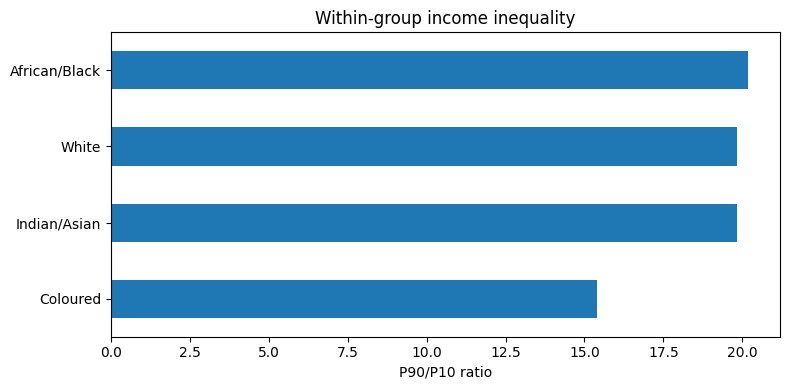

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
group_summary.sort_values('p90_p10')['p90_p10'].plot.barh(ax=ax)
ax.set(xlabel='P90/P10 ratio', ylabel='', title='Within-group income inequality')
plt.tight_layout()
plt.show()

## 3. Bootstrap uncertainty for the overall ratio

Resample the retained observations **with replacement** 1,000 times. The 2.5th and 97.5th percentiles of the bootstrap estimates form a percentile-based interval. This is a simple individual-level bootstrap and does not account for any survey clustering, stratification or weights.

In [5]:
rng = np.random.default_rng(422)
B = 1_000
n = len(income)
bootstrap_ratios = np.empty(B)
for i in range(B):
    sample = income[rng.integers(0, n, size=n)]
    bootstrap_ratios[i] = p90_p10(sample)
ci = np.quantile(bootstrap_ratios, [0.025, 0.975])
print(f'Estimate: {overall:.2f}')
print(f'Bootstrap standard error: {bootstrap_ratios.std(ddof=1):.3f}')
print(f'95% percentile interval: [{ci[0]:.2f}, {ci[1]:.2f}]')

Estimate: 23.41
Bootstrap standard error: 0.253
95% percentile interval: [22.75, 23.75]


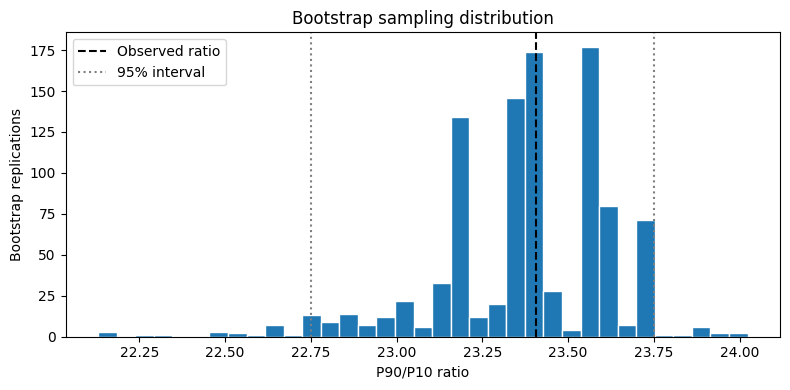

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(bootstrap_ratios, bins=35, edgecolor='white')
ax.axvline(overall, color='black', linestyle='--', label='Observed ratio')
ax.axvline(ci[0], color='gray', linestyle=':', label='95% interval')
ax.axvline(ci[1], color='gray', linestyle=':')
ax.set(xlabel='P90/P10 ratio', ylabel='Bootstrap replications', title='Bootstrap sampling distribution')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Compare within-group inequality

For an illustrative contrast, compare the African/Black and Coloured categories, which had the highest and lowest observed within-group ratios in this dataset. Because this contrast was selected **after examining the groups**, the interval is exploratory rather than a pre-specified confirmatory test.

Each group is resampled separately, preserving its observed sample size. This differs slightly from bootstrapping the pooled dataset and is intended to make the comparison transparent.

In [7]:
group_a = data.loc[data['population_group']=='African/Black', 'imputed_real'].to_numpy()
group_b = data.loc[data['population_group']=='Coloured', 'imputed_real'].to_numpy()
observed_diff = p90_p10(group_a) - p90_p10(group_b)
rng_groups = np.random.default_rng(407)
boot_diff = np.empty(B)
for i in range(B):
    a = group_a[rng_groups.integers(0, len(group_a), size=len(group_a))]
    b = group_b[rng_groups.integers(0, len(group_b), size=len(group_b))]
    boot_diff[i] = p90_p10(a) - p90_p10(b)
diff_ci = np.quantile(boot_diff, [0.025, 0.975])
print(f'Observed within-group ratio difference: {observed_diff:.2f}')
print(f'Bootstrap mean difference: {boot_diff.mean():.2f}')
print(f'95% percentile interval: [{diff_ci[0]:.2f}, {diff_ci[1]:.2f}]')
print(f'Share of bootstrap differences above zero: {(boot_diff > 0).mean():.1%}')

Observed within-group ratio difference: 4.80
Bootstrap mean difference: 5.12
95% percentile interval: [3.46, 7.00]
Share of bootstrap differences above zero: 100.0%


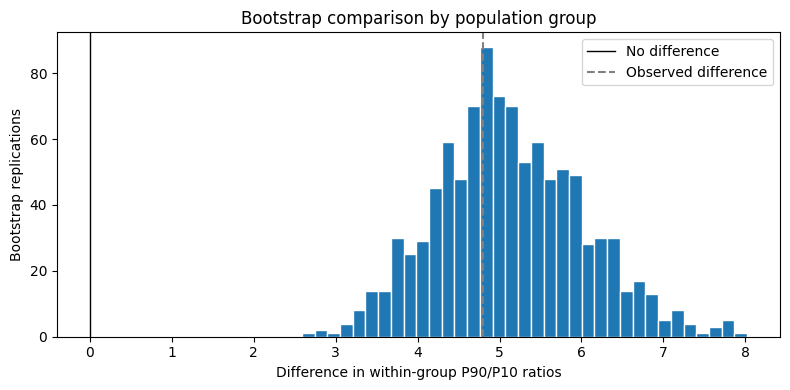

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_diff, bins=35, edgecolor='white')
ax.axvline(0, color='black', linewidth=1, label='No difference')
ax.axvline(observed_diff, color='gray', linestyle='--', label='Observed difference')
ax.set(xlabel='Difference in within-group P90/P10 ratios', ylabel='Bootstrap replications', title='Bootstrap comparison by population group')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Interpretation and limitations

- The observed overall P90/P10 ratio is approximately **23.41**: income at the 90th percentile is about 23 times income at the 10th percentile among non-missing records.
- The population-group results measure inequality **within** each category; they do not establish how much of overall inequality is due to income differences **between** groups.
- The bootstrap distribution may be irregular because quantiles can change in discrete jumps when many incomes are repeated or imputed. A percentile bootstrap does not require imposing a normal shape on the simulated estimates.
- Missing-income exclusions may create selection bias. The supplied extract has no survey design variables or weights, so the bootstrap intervals are conditional on this sample and resampling scheme.
- The analysis uses 2017 data and does not describe present-day conditions. Group comparisons are descriptive, not causal; the selected extreme-group contrast is exploratory.

**Possible extension:** Obtain the original survey design and weights, then compare design-aware uncertainty estimates against this illustrative simple bootstrap.